# Fig. 2a: Models optimized for reward

[AI generated summary] Probability of choosing the high-payoff target for the monkeys and for the models with parameters optimized to maximize reward (WSLS, standard RL, inferential RL, foraging). Dashed line: optimal model (HSMM).

**How to run:** run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/behav_modeling/optimizing` (see the README). To recompute them, run in this folder: `python run_model_optimizing.py` (Bayesian optimization of each model on simulated sessions; several hours).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from popy.config import COLORS
from helpers import load_optimizing_results

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_res(res_all, paper_format=False):
    # Set font size and figure size
    if paper_format:
        plt.rcParams.update({'font.size': 8})
        w, h = 4, 4
    else:
        plt.rcParams.update({'font.size': 8})
        w, h = 12, 5

    # Define the modes and figure
    modes = ['prop_best_target']
    fig, ax = plt.subplots(1, 1, figsize=(w/2.54, h/2.54))

    y_KA = 0.7742568470273881
    y_PO = 0.6373878299600445
    if not paper_format:
        ax.axhline(y=y_KA, color=COLORS['ka'], linestyle='--', linewidth=1, label='Monkey KA', zorder=10)
        ax.axhline(y=y_PO, color=COLORS['po'], linestyle='--', linewidth=1, label='Monkey PO', zorder=10)
    else:
        # add two bars for KA and PO monkeys by adding them to res_all dataframe with Model 'Monkey KA' and 'Monkey PO', and prop_best_target values y_KA and y_PO respectively, and then plot them as bars with the same color as the horizontal lines
        res_all = pd.concat([res_all, pd.DataFrame({'Model': ['Monkey KA'], 'prop_best_target': [y_KA]})], ignore_index=True)
        res_all = pd.concat([res_all, pd.DataFrame({'Model': ['Monkey PO'], 'prop_best_target': [y_PO]})], ignore_index=True)

        # mode monkeys to the first position
        res_all['Model'] = pd.Categorical(res_all['Model'], categories=['Monkey KA', 'Monkey PO'] + [model for model in res_all['Model'].unique() if model not in ['Monkey KA', 'Monkey PO']], ordered=True)
        res_all = res_all.sort_values('Model')

    # Get unique values
    models = res_all['Model'].unique()
    #monkeys = res_all.loc[res_all['monkey'] != 'yu_DCZ', 'monkey'].unique()

    # Set up positions
    x = np.arange(len(models))
    width = 0.65  # Width of bars        
    
    data = res_all
    values = [data.loc[data['Model'] == model, 'prop_best_target'].iloc[0] if len(data.loc[data['Model'] == model]) > 0 else 0 for model in models]
    
    # Create bars with model-based coloring
    for j, (model, value) in enumerate(zip(models, values)):
        hatch = None
        if model.split()[0] == 'Standard':
            # replace  what comes after with RL
            color = COLORS['Standard RL']
            if (not model == 'Standard RL - stickiness' and not paper_format) or (paper_format and not model == 'Standard RL'):
                hatch = '///'  # Dashed filling pattern
        elif model.split()[0] == 'Inferential':
            color = COLORS['Inferential RL']
            if (not model == 'Inferential RL - stickiness' and not paper_format) or (paper_format and not model == 'Inferential RL'):
                hatch = '///'  # Dashed filling pattern
        elif model.split()[0] == 'Foraging':
            color = COLORS['Foraging']
            if not len(model.split(" ")) == 1:
                hatch = '///'  # Dashed filling pattern
        else:
            color = COLORS.get(model, 'grey')
            hatch = None
        alpha = 0.8
        
        
        bar = ax.bar(x[j], value, width, 
            color=color, hatch=hatch,
            edgecolor='black', linewidth=0.5, alpha=alpha)
        
        # Set hatch color to grey for RL-s models
        if model.split()[-1] == 'RL-s':
            import matplotlib as mpl
            mpl.rcParams['hatch.color'] = 'grey'

    # plot horizontal lines: optimal, monkey KA and monkey PO:
    y_optimal = 0.89
    ax.axhline(y=y_optimal, color='black', linestyle='--', linewidth=1, label='Optimal', zorder=10)
    
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1), frameon=False)

    # Configure axes
    ax.set_ylim(0.40, 0.90)
    ax.set_yticks(np.arange(0.4, 1, 0.1))
    ax.set_ylabel('Prob. optimal target', fontsize=8)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    #ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

    ax.set_xticks(x)
    if paper_format:
        ax.set_xticklabels(models, rotation=45, horizontalalignment='right')
    else:
        ax.set_xticklabels(models, rotation=-90, horizontalalignment='center')    

    return fig, ax

---
# Load results

In [4]:
res_all = load_optimizing_results()

res_all

,Model,epsilon,alpha,alpha_unchosen,beta,V0,forgetting_rate,forgetting_threshold,stickiness_bias,b2,abandoned_bias,abandoned_decay,Reward rate,Proba best,alpha_threshold,prop_best_target
0,Repeating agent,0.047049,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.40514,0.33514,NaN,0.33514
1,Standard RL,NaN,0.837458,NaN,88.508907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.54917,0.72518,NaN,0.72518
2,Standard RL - forgetting,NaN,0.370099,NaN,70.047301,NaN,0.478145,0.254921,NaN,NaN,NaN,NaN,0.58341,0.80078,NaN,0.80078
3,Inferential RL - stickiness + spatial bias,NaN,0.146473,NaN,67.704908,NaN,NaN,NaN,3.295356,0.615347,NaN,NaN,0.58615,0.81077,NaN,0.81077
4,Standard RL - stickiness + forgetting,NaN,0.279223,NaN,86.148340,NaN,0.201793,0.322275,0.000000,NaN,NaN,NaN,0.58775,0.81198,NaN,0.81198
5,Inferential RL - stickiness + multiple alphas,NaN,0.038855,0.324777,100.000000,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.58707,0.80977,NaN,0.80977
6,Inferential RL,NaN,0.125499,NaN,93.958247,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.58262,0.80378,NaN,0.80378
7,Foraging - no reset,NaN,0.383080,NaN,100.000000,0.227917,NaN,NaN,NaN,NaN,NaN,NaN,0.57431,0.78213,NaN,0.78213
8,Foraging - abandoned bias,NaN,0.312361,NaN,91.340539,0.282397,NaN,NaN,NaN,NaN,-50.0,1.000000,0.58696,0.81228,NaN,0.81228
9,Foraging - abandoned bias + spatial bias,NaN,0.346199,NaN,86.309990,0.237994,NaN,NaN,NaN,0.695276,-50.0,0.136887,0.58802,0.81465,NaN,0.81465


In [5]:
# sort res_all 'Model' column by the order of keys in MODELS 

from run_model_optimizing import MODELS

model_order = list(MODELS.keys())
present_models = res_all["Model"].dropna().astype(str).unique().tolist()

# Keep only models that are present, then append unexpected ones
ordered_present = [m for m in model_order if m in present_models]
extra_present = [m for m in present_models if m not in ordered_present]
final_order = ordered_present + extra_present

res_all = (
    res_all.assign(
        Model=pd.Categorical(res_all["Model"], categories=final_order, ordered=True)
    )
    .sort_values("Model")
    .reset_index(drop=True)
)

res_all

,Model,epsilon,alpha,alpha_unchosen,beta,V0,forgetting_rate,forgetting_threshold,stickiness_bias,b2,abandoned_bias,abandoned_decay,Reward rate,Proba best,alpha_threshold,prop_best_target
0,WSLS,0.003483,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.48616,0.53406,NaN,0.53406
1,Standard RL - stickiness,NaN,0.831606,NaN,65.182717,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.54929,0.72275,NaN,0.72275
2,Inferential RL - stickiness,NaN,0.155827,NaN,75.936239,NaN,NaN,NaN,8.838768,NaN,NaN,NaN,0.58530,0.81050,NaN,0.81050
3,Foraging,NaN,0.301073,NaN,100.000000,0.302745,NaN,NaN,NaN,NaN,NaN,NaN,0.57490,0.78434,NaN,0.78434
4,HSMM,NaN,NaN,NaN,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.63600,0.88600,NaN,NaN
5,Repeating agent,0.047049,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.40514,0.33514,NaN,0.33514
6,Standard RL,NaN,0.837458,NaN,88.508907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.54917,0.72518,NaN,0.72518
7,Standard RL - forgetting,NaN,0.370099,NaN,70.047301,NaN,0.478145,0.254921,NaN,NaN,NaN,NaN,0.58341,0.80078,NaN,0.80078
8,Inferential RL - stickiness + spatial bias,NaN,0.146473,NaN,67.704908,NaN,NaN,NaN,3.295356,0.615347,NaN,NaN,0.58615,0.81077,NaN,0.81077
9,Standard RL - stickiness + forgetting,NaN,0.279223,NaN,86.148340,NaN,0.201793,0.322275,0.000000,NaN,NaN,NaN,0.58775,0.81198,NaN,0.81198


In [6]:
# performance of the optimal model (HSMM), shown as dashed line in Fig. 2a
print(res_all.loc[res_all['Model'] == 'HSMM', ['Model', 'Proba best']])

  Model  Proba best
4  HSMM       0.886


In [7]:
# remove Repeating agent and HSMM
res_all = res_all[~res_all['Model'].isin(['Repeating agent', 'HSMM'])]

---
# Fig. 2a

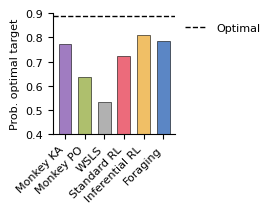

In [8]:
models_to_show = {
    'WSLS': 'WSLS',
    'Standard RL - stickiness': 'Standard RL',
    'Inferential RL - stickiness': 'Inferential RL',
    'Foraging': 'Foraging',
}

res_all_temp = res_all[res_all['Model'].isin(models_to_show.keys())].copy()
res_all_temp['Model'] = res_all_temp['Model'].map(models_to_show)

fig, ax = plot_res(res_all_temp, paper_format=True)

# Adjust layout and save as SVG if needed
#plt.tight_layout()
# Uncomment the following line to save the figure
plt.savefig(os.path.join(FIGS_PATH, 'fig2a_optimal_models.svg'), dpi=300, bbox_inches='tight', transparent=False)

plt.show()

In [9]:
# Export source data (Figure 2a)
from popy.source_data import export_source_data

# bar heights and dashed line, as drawn above (the monkeys' values are set in plot_res)
bars = pd.DataFrame({'Agent': [t.get_text() for t in ax.get_xticklabels()],
                     'Prob. optimal target': [p.get_height() for p in ax.patches]})
optimal_line = pd.DataFrame({'Line': ['Optimal model (HSMM), dashed line'],
                             'Prob. optimal target': [ax.lines[0].get_ydata()[0]]})
export_source_data('Figure 2a', {'Bars': bars, 'Dashed line': optimal_line},
                   'Probability of choosing the optimal (high-payoff) target. Bars: monkeys KA and PO (recorded choices) and the models '
                   'with parameters optimized to maximize reward (WSLS, standard RL, inferential RL, foraging; 100,000 simulated trials each); '
                   'dashed line: optimal model (HSMM; 0.886 in simulation, drawn at 0.89). Chance level: 0.33. No error bars.')

Figure 2a: source data saved (6 rows, 1 rows)
